# NER propre à Djibouti : reconnaître institutions, lieux, personnes et dates

**Projet TALN, Master 2 IAMD, Université de Djibouti.** Binôme 5 : Mako et Kadiga.

**Comment lire ce notebook.** De haut en bas, sans rien sauter. Chaque section dit ce qu'on fait, puis le montre.
Les chiffres ne sont **jamais tapés à la main** : ils viennent des fichiers du dossier `results/`, ou d'un calcul fait sous vos yeux.
Quand un résultat est lu dans un fichier, la cellule écrit « résultat lu depuis … ».

| # | Section |
|---|---|
| 1 | Le problème |
| 2 | Les données : le corpus de Kadiga et La Nation, avec le guide d'annotation |
| 3 | La référence : spaCy seul |
| 4 | Les approches : Kadiga (B, C, D) et nos règles (3a, 3b, 3c) |
| 5 | Le protocole : quel jeu sert à quoi, score exact et score tolérant |
| 6 | Le tableau comparatif |
| 7 | Dix erreurs analysées |
| 8 | Le surapprentissage |
| 9 | Limites et perspectives |
| 10 | Visualisation avec displaCy |

In [1]:
import csv
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import spacy
from IPython.display import Markdown, display


def trouver_racine():
    """Remonte les dossiers jusqu'à trouver la racine du projet (celle qui contient src/ et results/)."""
    p = Path.cwd().resolve()
    for dossier in [p, *p.parents]:
        if (dossier / "src" / "evaluate.py").exists() and (dossier / "results").exists():
            return dossier
    raise FileNotFoundError("racine du projet introuvable")


RACINE = trouver_racine()
sys.path.insert(0, str(RACINE / "src"))          # on IMPORTE le code de src/, on ne le recopie pas
RES, DATA = RACINE / "results", RACINE / "data"

import regles_locales as R          # nos règles 3a et nos filtres 3b (gelés)
import systemes_kadiga as K         # les systèmes A, B, C, D de Kadiga, repris à l'identique
from evaluate import evaluer, evaluer_tolerant

# Interrupteur : False = on LIT les résultats déjà calculés (rapide). True = on ré-entraîne D (plusieurs minutes).
RELANCER = False

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 90)
print("Racine du projet :", RACINE.name, "| spaCy", spacy.__version__, "| RELANCER =", RELANCER)

Racine du projet : taln-ner-djibouti | spaCy 3.8.18 | RELANCER = False


## 1. Le problème

**Question.** Peut-on retrouver automatiquement, dans des textes français de Djibouti, les **institutions, les lieux, les personnes et les dates** ?
On appelle cela la **reconnaissance d'entités nommées** (NER, de l'anglais *named entity recognition*).

**Exemple.** Dans « Le ministre Radwan Abdillahi Bahdon s'est rendu lundi 5 octobre à l'usine Douda Tazwid Industries » :
- `Radwan Abdillahi Bahdon` : une personne (PER) ;
- `lundi 5 octobre` : une date (DATE) ;
- `Douda Tazwid Industries` : une organisation (ORG).

**Les types** : PER (personne), ORG (institution, ministère, entreprise), LOC (lieu), DATE, FORMATION (diplôme). Le guide complet est à la section 2.

**Pourquoi c'est difficile.** Le modèle français de spaCy est entraîné sur des textes généraux. Il ne connaît pas les noms locaux
(`Ardo Bankoualé`, `Douda Tazwid Industries`) et il ne sait pas prédire les dates.

**Ce qu'on compare.**
- la référence : spaCy `fr_core_news_sm` seul ;
- trois approches de Kadiga : des règles générales (B), B plus un lexique local (C), un modèle ré-entraîné (D) ;
- nos approches : des règles locales (3a), des filtres selon le guide (3b), et des essais d'amélioration (3c).

**Une règle d'or de ce travail : ne jamais croire un score mesuré sur les textes qui ont servi à régler le système.**
La section 5 explique comment on s'en protège, et la section 8 montre ce que ça change.

## 2. Les données

On a **deux corpus qu'on ne mélange jamais** :
1. **Le corpus de Kadiga** : des phrases de textes publics (Wikipédia, Journal officiel, rapports Hcéres). Il a ses propres jeux `train`, `val`, `test`.
2. **La Nation** : des segments pris dans des articles de presse du journal *La Nation* (Djibouti), annotés à la main par Mako, avec le guide ci-dessous. Ils sont répartis en quatre jeux (tableau ci-dessous).

Les données sont publiques (articles de presse, textes officiels). Il n'y a pas de données personnelles.

### 2.1 Le corpus de Kadiga

In [2]:
CK = RACINE / "kadiga" / "data" / "corpus"
phrases_k = pd.read_csv(CK / "sentences.csv", encoding="utf-8")
entites_k = pd.read_csv(CK / "entities.csv", encoding="utf-8")
print("Corpus de Kadiga : lu depuis kadiga/data/corpus/sentences.csv et entities.csv")
tab_k = pd.crosstab(entites_k["label"], entites_k["split"])[["train", "val", "test"]]
tab_k.loc["TOTAL entités"] = tab_k.sum()
tab_k.loc["phrases"] = phrases_k["split"].value_counts()[["train", "val", "test"]]
tab_k

Corpus de Kadiga : lu depuis kadiga/data/corpus/sentences.csv et entities.csv


split,train,val,test
label,,,
DATE,55,6,18
FORM,4,10,5
LOC,83,8,13
ORG,51,27,28
PER,14,5,4
TOTAL entités,207,56,68
phrases,84,26,27


### 2.2 La Nation : nos 4 jeux

Chaque jeu est fait d'articles différents. **Aucun article n'est dans deux jeux.** Le choix des segments est reproductible (on prend des segments
régulièrement espacés dans l'article, sans hasard, et on enlève les segments de moins de 8 tokens).

In [3]:
def lire_csv(chemin):
    with open(chemin, encoding="utf-8", newline="") as f:
        return list(csv.DictReader(f))


CORPUS = {"dev": [], "test": [], "test2": [], "test3": []}      # jeu -> segments
for fichier in ["corpus_ner.csv", "corpus_test2.csv", "corpus_test3.csv"]:
    for s in lire_csv(DATA / fichier):
        CORPUS[s["split"]].append(s)
ANNOT = []
for fichier in ["annotations.csv", "annotations_test2.csv", "annotations_test3.csv"]:
    ANNOT += lire_csv(DATA / fichier)

lignes = []
for jeu, segs in CORPUS.items():
    ids = {s["id"] for s in segs}
    ann = [a for a in ANNOT if a["id_segment"] in ids]
    ligne = {"jeu": jeu, "articles": ", ".join(sorted({i.split("_")[0] for i in ids})),
             "segments": len(segs), "segments avec entité": len({a["id_segment"] for a in ann})}
    for t in ["PER", "ORG", "LOC", "DATE", "FORMATION"]:
        ligne[t] = sum(1 for a in ann if a["type"] == t)
    ligne["total entités"] = len(ann)
    ligne["lignes à vérifier"] = sum(1 for a in ann if a["a_verifier"] == "oui")
    lignes.append(ligne)
print("La Nation : calculé depuis data/corpus_*.csv et data/annotations*.csv")
tab_nation = pd.DataFrame(lignes).set_index("jeu")

# Total calculé (jamais tapé à la main) + contrôles : aucun segment ni aucun article dans deux jeux.
tous_les_ids = [s["id"] for segs in CORPUS.values() for s in segs]
articles_par_jeu = {jeu: {s["id"].split("_")[0] for s in segs} for jeu, segs in CORPUS.items()}
tous_les_articles = sorted({a for arts in articles_par_jeu.values() for a in arts})
assert len(tous_les_ids) == len(set(tous_les_ids)), "un segment est présent deux fois"
assert sum(len(a) for a in articles_par_jeu.values()) == len(tous_les_articles), "un article est dans deux jeux"
print(f"TOTAL La Nation : {len(tous_les_ids)} segments dans {len(tous_les_articles)} articles "
      f"({len(tous_les_ids) / len(tous_les_articles):.0f} segments par article en moyenne). "
      "Contrôle : aucun segment et aucun article n'est dans deux jeux.")
tab_nation

La Nation : calculé depuis data/corpus_*.csv et data/annotations*.csv
TOTAL La Nation : 210 segments dans 15 articles (14 segments par article en moyenne). Contrôle : aucun segment et aucun article n'est dans deux jeux.


,articles,segments,segments avec entité,PER,ORG,LOC,DATE,FORMATION,total entités,lignes à vérifier
jeu,,,,,,,,,,
dev,"A01, A02, A08, A10, A12, A14",84,31,14,17,16,10,0,57,2
test,"A03, A11, A15",42,17,7,13,4,3,0,27,6
test2,"A07, A09, A13",42,12,1,6,6,3,0,16,5
test3,"A04, A05, A06",42,18,0,5,18,4,0,27,7


**À retenir.** Les jeux sont **petits** (regardez la colonne « total entités »). FORMATION n'apparaît nulle part : on n'en a pas inventé.
Le jeu `test3` n'a **aucune personne**. On y revient dans les limites (section 9).

### 2.3 Le guide d'annotation

C'est le texte qu'on a suivi pour annoter **tous** les jeux de La Nation, de la même façon. Il est lu depuis `docs/guide_annotation.md`.

In [4]:
display(Markdown((RACINE / "docs" / "guide_annotation.md").read_text(encoding="utf-8")))

# Guide d'annotation NER (français, presse de Djibouti)

On annote le texte brut, à la main, sans modèle. Une entité = un début, une fin (en caractères, fin exclue) et un type. Ces règles sont appliquées partout de la même façon.

## Les 5 types

| Type | Définition | Exemples |
|---|---|---|
| ORG | institution, ministère, fédération, entreprise, organisation, organe constitué | Fédération djiboutienne de football, ministère de la Jeunesse et de la Culture |
| LOC | lieu : pays, ville, quartier, localité, bâtiment ou site nommé | Djibouti, Tadjourah, Ardo Bankoualé, Théâtre des Salines |
| PER | personne, par son nom propre | Louise Mushikiwabo, Radwan Abdillahi Bahdon |
| DATE | date ou moment ancré dans le calendrier | lundi 5 octobre, 2026-2027 |
| FORMATION | diplôme, master, filière | master en santé publique |

## Règles générales
- **Une seule annotation par endroit** : pas de chevauchement, pas d'entité dans une entité. On prend la plus longue.
  Ex. : « Fédération djiboutienne de football » = 1 ORG (on n'annote pas « Djibouti » dedans).
- **Le nom propre seulement** : pas d'article (« le », « les ») ni de ponctuation.
- **Doute** : on annote selon la règle la plus proche et on met `a_verifier = oui` avec une remarque.

## Cas difficiles

**Mentions courtes** : « la Fédération », « l'Organisation », « le Comité » (nom court avec article, sans le nom complet) → non annotées. On annote le nom complet seulement.

**Fonction ou personne**
- Une fonction seule n'est pas une entité : « le ministre de l'Agriculture » → rien.
- Le nom qui suit est PER : « Radwan Abdillahi Bahdon » → PER.

**Titre devant un nom** : le titre n'est **pas** dans PER. On annote le nom seul.
- « Dr Maad Nasser Mohamed » → PER = « Maad Nasser Mohamed ».
- « Me Abeyazide » → PER = « Abeyazide ».
- « l'inspecteur général Moussa Ali Mohamed » → PER = « Moussa Ali Mohamed ».

**ORG**
- Le mot « ministère » / « secrétariat » fait partie de l'entité : « ministère de la Jeunesse et de la Culture » = 1 ORG ; « Secrétariat d'État chargé des Sports » = 1 ORG.
- Organe d'une organisation (« Comité directeur », « Comité ad hoc ») → ORG, `a_verifier = oui`.
- ORG qui contient un lieu : une seule ORG, on n'annote pas le lieu dedans. « Coopérative artisanale des femmes d'Ardo », « Conseil régional de Tadjourah » → 1 ORG chacune.
- « Programme élargi de vaccination » → ORG, `a_verifier = oui`.
- Groupement d'États (« BRICS », « G20 ») → ORG, `a_verifier = oui`.
- « Assemblée générale extraordinaire » est une réunion, donc un événement → non annoté.

**Sigles** : deux annotations, même type, quand la forme longue et le sigle sont écrits.
- « Fédération djiboutienne de football (FDF) » → ORG « Fédération djiboutienne de football » + ORG « FDF ».
- Un sigle seul (OIF, OMS) → 1 ORG. MENFOP est le sigle d'un ministère → ORG.

**Lieux**
- « Djibouti » est LOC partout (pays, ville ou gouvernement). « République de Djibouti » = 1 LOC.
- « Théâtre des Salines » : lieu où se passe l'événement → LOC.
- « école de la Zone portuaire Sud » → LOC = « Zone portuaire Sud » seulement (« école » est un nom commun).
- Un nom commun descriptif (école, aéroport) n'est pas annoté ; on garde le nom propre : « aéroport international de Djibouti » → LOC = « Djibouti ».
- Les adjectifs (« djiboutien ») ne sont pas annotés.

**Dates**
- DATE : jour + date (« lundi 5 octobre »), plage (« 30 et 31 août 2026 », « 6, 7 et 8 octobre »), date simple (« 7 octobre »), année ou année scolaire (« 2026-2027 »). On n'inclut ni « les » ni « jusqu'au ».
- Jour de semaine seul (« lundi ») → DATE.
- « jeudi soir » → DATE entière, `a_verifier = oui`.
- Pas de DATE pour les dates relatives sans repère : « cette année », « aujourd'hui », « l'an dernier ».
- « fin de », « début de », « mi- » + date : exclus de la DATE. On annote « mars 2026 », pas « fin de mars 2026 ».

**Événements** : hors types, donc non annotés (« Activités Estivales 2026 », « Challenge intercommunautaire culturel et sportif », « Mission économique de la Francophonie en Afrique de l'Est »). On n'annote rien à l'intérieur du nom de l'événement (règle « pas d'entité dans une entité »).

**Hors types** : les textes officiels et les programmes de loi (« Defence Procurement Procedure ») ne sont pas annotés ; les notions géopolitiques (« Sud global ») non plus.

**FORMATION** : le nom du diplôme ou de la filière, sans le verbe (« obtenir un master en droit » → « master en droit »). Si le corpus n'a aucun cas, on n'en invente pas.

## Notes pour l'évaluation
- `fr_core_news_sm` ne prédit que PER, ORG, LOC et MISC. Il ne prédit ni DATE ni FORMATION.
- DATE sera donc évaluée à part (baseline avec règles `EntityRuler`).


## 3. La référence : spaCy seul

On passe les textes dans le modèle français de spaCy, **sans aucune règle ajoutée**. C'est le point de départ, appelé **A**.

**Fiche du modèle** (pour la documentation) :

In [5]:
nlp_a = spacy.load("fr_core_news_sm")
meta = nlp_a.meta
print("Modèle            :", meta["lang"] + "_" + meta["name"], "| version", meta["version"])
print("Étiquettes du NER :", nlp_a.get_pipe("ner").labels)
print("Données d'entraînement :", [s["name"] for s in meta["sources"]])
print("Limites : modèle petit (sm) ; textes généraux, pas la presse de Djibouti ; ne prédit NI DATE NI FORMATION.")

texte = next(s["fr"] for s in CORPUS["test"] if s["id"] == "A03_S008")
print("\nExemple (A03_S008) :", texte)
print("spaCy seul         :", [(e.text, e.label_) for e in nlp_a(texte).ents])

Modèle            : fr_core_news_sm | version 3.8.0
Étiquettes du NER : ('LOC', 'MISC', 'ORG', 'PER')
Données d'entraînement : ['UD French Sequoia v2.8', 'WikiNER', 'spaCy lookups data']
Limites : modèle petit (sm) ; textes généraux, pas la presse de Djibouti ; ne prédit NI DATE NI FORMATION.

Exemple (A03_S008) : Deux représentants du Secrétariat d'État chargé des Sports, l'inspecteur général Moussa Ali Mohamed et le directeur des Régions Omar Hassan Abdillahi, ont également assisté aux travaux en qualité d'observateurs.
spaCy seul         : [("Secrétariat d'État", 'ORG'), ('Sports', 'ORG'), ('Régions', 'LOC'), ('Omar Hassan Abdillahi', 'PER')]


**Ce que ça montre.** spaCy coupe « Secrétariat d'État chargé des Sports » en deux morceaux, et prend « Régions » pour un lieu.
Il utilise aussi l'étiquette `MISC` (divers), que notre guide n'a pas : on l'ignore.

### Lire les résultats
Les mesures ont été faites par des scripts de `src/` et rangées dans `results/`. Cette fonction les range **toutes dans un seul tableau**,
en donnant les mêmes noms aux mêmes systèmes. Elle ne calcule aucun score.

In [6]:
def nom_systeme(s):
    if "3a+3b" in s:
        return "3a+3b (= 3c)"
    if s.startswith("3a"):
        return "3a"
    for lettre in "BCD":
        if s.startswith(f"Kadiga {lettre}") or s.startswith(f"{lettre} –"):
            return f"Kadiga {lettre}"
    if s.startswith("A"):
        return "A"
    raise ValueError(s)


TYPE_NORM = {"TOUT PER+ORG+LOC+DATE": "TOUT (PER+ORG+LOC+DATE)", "TOUT PER+ORG+LOC": "TOUT (PER+ORG+LOC)"}
TYPES_AFFICHES = ["PER", "ORG", "LOC", "DATE", "TOUT (PER+ORG+LOC+DATE)", "TOUT (PER+ORG+LOC)"]


def lire_resultat(nom):
    print(f"résultat lu depuis results/{nom}")
    return pd.read_csv(RES / nom, encoding="utf-8-sig")


def charger_tous_les_resultats():
    lignes = []

    def ajouter(df, jeu, c_sys, c_type, c_sup, c_f1, c_tol, source):
        for _, r in df.iterrows():
            t = TYPE_NORM.get(r[c_type], r[c_type])
            if t in TYPES_AFFICHES:
                lignes.append({"jeu": jeu, "système": nom_systeme(r[c_sys]), "type": t, "support": r[c_sup],
                               "F1 exact": r[c_f1], "F1 tolérant": r[c_tol], "source": source})

    d = lire_resultat("scores_dev_test1.csv")
    for jeu in ["dev", "test"]:
        ajouter(d[d["jeu"] == jeu], jeu, "système", "type", "support", "exact F1", "tolérant F1", "scores_dev_test1.csv")
    e = lire_resultat("test_externe_lanation.csv")
    for perimetre, jeu in [("dev (84)", "dev"), ("test (42)", "test")]:
        ajouter(e[e["périmètre"] == perimetre], jeu, "système", "type", "support", "F1", "tolérant F1", "test_externe_lanation.csv")
    t2 = lire_resultat("test2_resultats.csv")
    ajouter(t2, "test2", "système", "type", "support (gold)", "exact F1", "tolérant F1", "test2_resultats.csv")
    t3 = lire_resultat("test3.csv")
    ajouter(t3, "test3", "système", "type", "support", "exact F1", "tolérant F1", "test3.csv")
    return pd.DataFrame(lignes)


BRUT = charger_tous_les_resultats()

# Contrôle de cohérence : le système A apparaît dans deux fichiers pour dev et test. Les deux doivent donner les mêmes nombres.
doublons = BRUT.groupby(["jeu", "système", "type"])[["F1 exact", "F1 tolérant"]].agg(lambda x: x.max() - x.min())
ecart = float(doublons.max().max())
print(f"\nContrôle de cohérence entre fichiers : écart maximal = {ecart:.4f} -> {'OK' if ecart < 1e-3 else 'PROBLÈME'}")
TOUS = BRUT.drop_duplicates(["jeu", "système", "type"]).reset_index(drop=True)
print(len(TOUS), "mesures rangées dans un seul tableau")

résultat lu depuis results/scores_dev_test1.csv
résultat lu depuis results/test_externe_lanation.csv
résultat lu depuis results/test2_resultats.csv
résultat lu depuis results/test3.csv

Contrôle de cohérence entre fichiers : écart maximal = 0.0000 -> OK
126 mesures rangées dans un seul tableau


In [7]:
ORDRE_SYS = ["A", "Kadiga B", "Kadiga C", "Kadiga D", "3a", "3a+3b (= 3c)"]
JEUX = ["dev", "test", "test2", "test3"]
ETIQUETTE = {"dev": "dev (optimiste)", "test": "test (optimiste)", "test2": "test2 (regardé)", "test3": "test3 (jamais vu)"}


def tableau(type_, colonne="F1 exact"):
    """Un système par ligne, un jeu par colonne. « non mesuré » = on n'a pas fait cette mesure ; « n/d » = non calculable."""
    lignes = []
    for s in ORDRE_SYS:
        ligne = {"système": s}
        for j in JEUX:
            sel = TOUS[(TOUS.jeu == j) & (TOUS.système == s) & (TOUS.type == type_)]
            if sel.empty:
                ligne[ETIQUETTE[j]] = "non mesuré"
            else:
                v = sel.iloc[0][colonne]
                ligne[ETIQUETTE[j]] = "n/d" if pd.isna(v) else f"{v:.3f}"
        lignes.append(ligne)
    sup = {"système": "support (entités réelles)"}
    for j in JEUX:
        sel = TOUS[(TOUS.jeu == j) & (TOUS.type == type_)]
        sup[ETIQUETTE[j]] = int(sel["support"].iloc[0]) if not sel.empty else "?"
    lignes.append(sup)
    return pd.DataFrame(lignes).set_index("système")


print("spaCy seul (A) : F1 exact par type et par jeu")
a_par_type = pd.DataFrame({t: tableau(t).loc["A"] for t in TYPES_AFFICHES}).T
a_par_type

spaCy seul (A) : F1 exact par type et par jeu


,dev (optimiste),test (optimiste),test2 (regardé),test3 (jamais vu)
PER,0.629,0.545,0.000,n/d
ORG,0.611,0.562,0.400,0.571
LOC,0.533,0.364,0.556,0.789
DATE,0.000,0.000,0.000,0.000
TOUT (PER+ORG+LOC+DATE),0.540,0.491,0.400,0.680
TOUT (PER+ORG+LOC),0.586,0.519,0.438,0.739


**Lecture.** « n/d » veut dire : impossible à calculer (par exemple, aucune personne à trouver dans `test3`).
Pour A, **DATE vaut 0** partout : spaCy ne sait pas prédire les dates. C'est la limite principale de la référence.

## 4. Les approches

### 4.1 Les trois approches de Kadiga (B, C, D)

Le code est dans `src/systemes_kadiga.py`. Il reprend **à l'identique** le notebook de Kadiga (`kadiga/TP_NER_Djibouti_Binome5.ipynb`).
Aucune règle n'est changée.

| Système | Idée en une phrase |
|---|---|
| **B** | spaCy + un `EntityRuler` : des règles **générales** (dates, « Université de … », « lac … », diplômes) |
| **C** | B + un **lexique local** construit sur la partie `train` de son corpus |
| **D** | on **ré-entraîne** le NER de spaCy sur le `train` de son corpus (arrêt anticipé sur sa validation) |

Un `EntityRuler` est un composant qui marque des entités avec des règles écrites à la main, **avant** le modèle statistique.

In [8]:
train_k = K.charger("train")
print("B : nombre de règles génériques :", len(K.patterns_generiques()))
print("C : nombre d'entrées du lexique construit sur son train :", len(K.lexique_train(train_k)))
print("D : paramètres -> graine", K.SEED, "| époques max", K.MAX_EPOCHS, "| patience", K.PATIENCE,
      "| lot", K.BATCH, "| dropout", K.DROPOUT)
print("D : nombre de phrases d'entraînement :", len(train_k))

B : nombre de règles génériques : 74
C : nombre d'entrées du lexique construit sur son train : 98
D : paramètres -> graine 42 | époques max 40 | patience 6 | lot 8 | dropout 0.3
D : nombre de phrases d'entraînement : 84


### 4.2 Nos règles : 3a, 3b, 3c

Le code est dans `src/regles_locales.py` (**gelé** : on ne le modifie plus) et `src/regles_3c.py`.

**3a : règles locales (avant le modèle).** Plusieurs groupes de règles, écrits en regardant le **dev** seulement ou à partir de connaissances générales.

In [9]:
lignes = []
for nom, regles in R.GROUPES.items():
    n = "composant à part (titre + nom)" if regles == "composant" else len(regles)
    lignes.append({"groupe": nom, "nombre de règles": n, "provenance": R.SOURCES[nom]})
pd.DataFrame(lignes).set_index("groupe")

,nombre de règles,provenance
groupe,,
dates,6,"dates : mois et jours = connaissance du français ; formes (5 octobre, 6, 7 et 8 octobr..."
org_ministeres,8,« ministère de… » / « Secrétariat d'État chargé… » : demandé dans la consigne (3a) ; a...
org_organes,4,« Comité … » / « Conseil régional » : demandé dans la consigne (3a) / règles du guide
org_entreprises,1,"« X Y Industries » : forme vue dans le DEV (A02), écrite de façon générale"
lexique_org,23,mélange : entrées vues dans le DEV + institutions connues a priori (voir LEXIQUE_ORG)
lexique_loc,28,"mélange : entrées vues dans le DEV + pays, régions, villes connues a priori (voir LEXI..."
per_titres,composant à part (titre + nom),"titre + nom : consigne (3a) ; formes vues dans le DEV (« Secrétaire générale, Louise… »)"


**Un exemple de 3a** : sur ces phrases inventées, chaque règle fait son travail (c'est du code, pas un résultat de mesure).

In [10]:
nlp_3a = R.construire(groupes=list(R.GROUPES))
for phrase in ["La réunion aura lieu mardi 3 mars à Obock.",
               "Elle travaille au ministère de la Santé et de la Population.",
               "Le Dr Yacin Moussa a ouvert la séance."]:
    print(phrase, "->", [(e.text, e.label_) for e in nlp_3a(phrase).ents])

La réunion aura lieu mardi 3 mars à Obock. -> [('mardi 3 mars', 'DATE'), ('Obock', 'LOC')]
Elle travaille au ministère de la Santé et de la Population. -> [('ministère de la Santé et de la Population', 'ORG')]
Le Dr Yacin Moussa a ouvert la séance. -> [('Yacin Moussa', 'PER')]


**3b : filtres après le modèle (selon le guide).** Des filtres enlèvent ou corrigent des entités qui ne respectent pas notre guide :

In [11]:
descriptions = {
    "minuscule": "une entité qui commence par une minuscule est un mot commun (sauf « ministère »)",
    "fonction": "une fonction (« Secrétaire générale de l'… ») n'est pas une entité",
    "mention_courte": "« l'Organisation », « la Fédération » seuls ne sont pas annotés",
    "evenement": "les événements (« Challenge… », « Mission économique… ») sont hors types",
    "titre_per": "le titre (« Me », « Dr ») reste hors du PER",
    "debut_phrase": "un mot commun en début de phrase n'est pas un nom propre",
    "domaines_ministre": "les domaines d'un ministre (« de l'Eau, de la Pêche ») ne sont pas des lieux",
    "extension_per": "un nom de personne s'étend aux mots voisins qui ressemblent à un nom",
}
pd.DataFrame({"filtre": R.FILTRES_3B_FINAL, "ce qu'il fait": [descriptions[f] for f in R.FILTRES_3B_FINAL]}).set_index("filtre")

,ce qu'il fait
filtre,
minuscule,une entité qui commence par une minuscule est un mot commun (sauf « ministère »)
fonction,une fonction (« Secrétaire générale de l'… ») n'est pas une entité
mention_courte,"« l'Organisation », « la Fédération » seuls ne sont pas annotés"
evenement,"les événements (« Challenge… », « Mission économique… ») sont hors types"
titre_per,"le titre (« Me », « Dr ») reste hors du PER"
debut_phrase,un mot commun en début de phrase n'est pas un nom propre
domaines_ministre,"les domaines d'un ministre (« de l'Eau, de la Pêche ») ne sont pas des lieux"
extension_per,un nom de personne s'étend aux mots voisins qui ressemblent à un nom


La version **3a+3b** est **gelée** : on ne la modifie plus (commit `087deb3`).

**3c : des essais d'amélioration, tous refusés.** Sur les 12 articles déjà vus, on a essayé : un plus gros modèle (`md`, `lg`), une règle pour « Djibouti »,
une règle pour une année seule, une règle pour les noms d'habitants. Les critères étaient fixés **avant** de voir les chiffres :
un gain d'au moins +0.02 de F1 exact, un F1 tolérant qui ne baisse pas de plus de 0.005, et au moins 2 segments changés.

In [12]:
essais = lire_resultat("essais_3c.csv")
essais

résultat lu depuis results/essais_3c.csv


,essai,F1 exact avant,F1 exact après,F1 tolérant avant,F1 tolérant après,segments changés,gardé,pourquoi
0,a) modèle md,0.902,0.898,0.922,0.917,11,non,gain exact -0.004 < +0.02
1,a) modèle lg,0.902,0.910,0.922,0.930,11,non,gain exact +0.008 < +0.02
2,"b1) « Djibouti » (1re version : rattrapage AVANT le filtre, fautive)",0.902,0.897,0.922,0.916,1,non,gain exact -0.005 < +0.02; tolérant baisse de -0.005; change seulement 1 segment (règl...
3,b2) « Djibouti » ne coupe pas une ORG (rattrapage APRÈS le filtre),0.902,0.902,0.922,0.922,0,non,gain exact +0.000 < +0.02; change seulement 0 segment (règle pour un seul exemple)
4,c) année seule en contexte,0.902,0.907,0.922,0.927,1,non,gain exact +0.005 < +0.02; change seulement 1 segment (règle pour un seul exemple)
5,d) noms d'habitants,0.902,0.911,0.922,0.931,2,non,gain exact +0.009 < +0.02


**Résultat : aucun essai n'est gardé.** Donc **3c est identique à 3a+3b**. On ne la mesure pas deux fois.
Le modèle `lg` est très gros (plus de 500 Mo) : il n'est pas dans Git, et on ne l'utilise pas.

### 4.3 L'interrupteur `RELANCER`
Ré-entraîner D prend plusieurs minutes. Par défaut (`RELANCER = False`), le notebook **lit** les résultats déjà calculés.
Avec `RELANCER = True`, il ré-entraîne D, vérifie qu'on retrouve le tableau de Kadiga, puis refait la mesure de D sur `test3`.

In [13]:
def mesurer_D_sur_test3():
    from mesurer_test2 import liste, predictions_kadiga
    from mesurer_test3 import calcul
    systemes_k = K.construire_systemes(verbeux=False)
    ok, _, _, ecarts = K.verifier_contre_kadiga(systemes_k)
    print("Le tableau de Kadiga est retrouvé :", ok, "| écart maximal :", float(ecarts.max().max()))
    segs = CORPUS["test3"]
    ids = [s["id"] for s in segs]
    gold = {i: [] for i in ids}
    for a in ANNOT:
        if a["id_segment"] in gold:
            gold[a["id_segment"]].append((int(a["debut"]), int(a["fin"]), a["type"]))
    preds = predictions_kadiga(systemes_k["D"], segs)
    r = calcul(liste(gold, ids, K_TYPES4), liste(preds, ids, K_TYPES4), "TOUT")
    return r[5], r[8]


K_TYPES4 = ["PER", "ORG", "LOC", "DATE"]
if RELANCER:
    debut = time.time()
    f1_exact, f1_tol = mesurer_D_sur_test3()
    lu = TOUS[(TOUS.jeu == "test3") & (TOUS.système == "Kadiga D") & (TOUS.type == "TOUT (PER+ORG+LOC+DATE)")].iloc[0]
    print(f"D recalculé sur test3 : F1 exact {f1_exact:.3f} | F1 tolérant {f1_tol:.3f} ({time.time() - debut:.0f} s)")
    print(f"D lu dans results/test3.csv : F1 exact {lu['F1 exact']:.3f} | F1 tolérant {lu['F1 tolérant']:.3f}")
else:
    print("RELANCER = False : les résultats de D sont LUS depuis results/test3.csv, results/test2_resultats.csv,")
    print("results/test_externe_lanation.csv et kadiga/results/tableau_comparatif.csv.")

RELANCER = False : les résultats de D sont LUS depuis results/test3.csv, results/test2_resultats.csv,
results/test_externe_lanation.csv et kadiga/results/tableau_comparatif.csv.


## 5. Le protocole : quel jeu sert à quoi

Un système qui est réglé sur des textes obtient un bon score sur **ces** textes. Cela ne dit pas qu'il marchera sur de nouveaux textes.
Pour ne pas se tromper, on sépare les jeux et on dit à quoi chacun a servi.

| Jeu | Articles | Rôle | Statut du score |
|---|---|---|---|
| `dev` | A01, A02, A08, A10, A12, A14 | on a écrit les règles 3a et 3b en regardant ses erreurs | **optimiste** |
| `test` | A03, A11, A15 | contrôle des règles ; je l'ai lu en entier pour annoter | **optimiste** |
| `test2` | A07, A09, A13 | mesuré une fois, puis ses erreurs ont été lues ; il a servi aux essais 3c | **regardé** : ne prouve plus rien |
| `test3` | A04, A05, A06 | annoté sans regarder aucune prédiction ; **mesuré une seule fois** | **la seule mesure honnête** |

(Les listes d'articles sont recalculées plus haut, section 2.2.) Pour le corpus de Kadiga, c'est un autre protocole, le sien :
`train` (construit le lexique, entraîne D), `val` (règle les règles, arrête D), `test` (lu une seule fois).

### Score exact et score tolérant
- **exact** : l'entité prédite doit avoir le **même début, la même fin et le même type** que l'entité réelle ;
- **tolérant** : même **type** et les positions se **chevauchent** d'au moins un caractère.

Le tolérant sépare les erreurs de **frontière** (on a trouvé l'entité, mais pas tout à fait au bon endroit) des **vraies** erreurs. Exemple calculé :

In [14]:
texte = "Le CRMN est à l'Université de Djibouti."
reel = [[(3, 7, "ORG"), (16, 38, "ORG")]]
prevu = [[(3, 7, "ORG"), (16, 26, "ORG")]]          # « Université » seul : la frontière est trop courte
for nom, f in [("exact", evaluer), ("tolérant", evaluer_tolerant)]:
    p, r, f1, s = f(reel, prevu)["TOUT"]
    print(f"{nom:9} précision {p:.2f} | rappel {r:.2f} | F1 {f1:.2f}   (2 entités réelles)")

exact     précision 0.50 | rappel 0.50 | F1 0.50   (2 entités réelles)
tolérant  précision 1.00 | rappel 1.00 | F1 1.00   (2 entités réelles)


**Précaution : on vérifie que nos chiffres sont reproductibles.** Les systèmes A, 3a et 3a+3b sont rapides.
On les **recalcule ici** et on les compare à ce que contiennent les fichiers de `results/`.

In [15]:
from mesurer_test2 import liste, predictions_spacy
from mesurer_test3 import calcul

NLP = {"A": R.construire(groupes=[]),
       "3a": R.construire(groupes=list(R.GROUPES)),
       "3a+3b (= 3c)": R.construire(groupes=list(R.GROUPES), filtres=list(R.FILTRES_3B_FINAL))}


def f1_vivant(nlp, jeu):
    segs = CORPUS[jeu]
    ids = [s["id"] for s in segs]
    gold = {i: [] for i in ids}
    for a in ANNOT:
        if a["id_segment"] in gold:
            gold[a["id_segment"]].append((int(a["debut"]), int(a["fin"]), a["type"]))
    preds = predictions_spacy(nlp, segs)
    r = calcul(liste(gold, ids, K_TYPES4), liste(preds, ids, K_TYPES4), "TOUT")
    return r[5], r[8]                              # F1 exact, F1 tolérant


debut = time.time()
lignes, pire = [], 0.0
for nom, nlp in NLP.items():
    for jeu in JEUX:
        lu = TOUS[(TOUS.jeu == jeu) & (TOUS.système == nom) & (TOUS.type == "TOUT (PER+ORG+LOC+DATE)")]
        if lu.empty:
            continue                                # 3a et 3a+3b n'ont pas de mesure pour tous les jeux
        ex, tol = f1_vivant(nlp, jeu)
        e = max(abs(ex - lu.iloc[0]["F1 exact"]), abs(tol - lu.iloc[0]["F1 tolérant"]))
        pire = max(pire, e)
        lignes.append({"système": nom, "jeu": jeu, "F1 exact recalculé": round(ex, 3), "F1 exact du fichier": round(lu.iloc[0]["F1 exact"], 3),
                       "écart": round(e, 4)})
print(f"Recalcul en {time.time() - debut:.0f} s. Écart maximal avec les fichiers de results/ : {pire:.4f} -> {'OK' if pire < 1e-3 else 'PROBLÈME'}")
pd.DataFrame(lignes).set_index(["système", "jeu"])

Recalcul en 8 s. Écart maximal avec les fichiers de results/ : 0.0000 -> OK


F1 exact recalculé  F1 exact du fichier  écart
système      jeu                                                  
A            dev                 0.540                0.540    0.0
             test                0.491                0.491    0.0
             test2               0.400                0.400    0.0
             test3               0.680                0.680    0.0
3a           dev                 0.803                0.803    0.0
             test                0.794                0.794    0.0
             test2               0.526                0.526    0.0
3a+3b (= 3c) dev                 0.991                0.991    0.0
             test                0.909                0.909    0.0
             test2               0.588                0.588    0.0
             test3               0.745                0.745    0.0

## 6. Le tableau comparatif

**Deux tableaux séparés, parce que ce sont deux corpus différents** (textes, tailles et protocoles différents). On ne les compare pas entre eux.

### 6.1 Le corpus de Kadiga (son `test`)
Pour ce corpus, chaque système est mesuré avec le protocole de Kadiga. Seul le score exact existe.

In [16]:
tab_kadiga = pd.read_csv(RACINE / "kadiga" / "results" / "tableau_comparatif.csv", encoding="utf-8-sig").set_index("système")
print("résultat lu depuis kadiga/results/tableau_comparatif.csv (corpus de Kadiga, son test)")
print("Phrases du test de Kadiga :", int((phrases_k['split'] == 'test').sum()), "| entités :", int((entites_k['split'] == 'test').sum()))
tab_kadiga

résultat lu depuis kadiga/results/tableau_comparatif.csv (corpus de Kadiga, son test)
Phrases du test de Kadiga : 27 | entités : 68


,P micro,R micro,F1 micro,F1 macro,F1 ORG,F1 LOC,F1 PER,F1 DATE,F1 FORM
système,,,,,,,,,
A – spaCy seul,0.400,0.441,0.420,0.296,0.507,0.564,0.286,0.000,0.0
B – + règles génériques,0.438,0.676,0.532,0.470,0.448,0.564,0.286,0.791,0.2
C – + lexique local (train),0.467,0.735,0.571,0.502,0.493,0.650,0.308,0.791,0.2
D – spaCy ré-entraîné (train),0.576,0.721,0.641,0.536,0.667,0.765,0.571,0.571,0.0


**Lecture.** Sur son corpus, D (le modèle ré-entraîné) a le meilleur F1 micro. Les règles de B et C font monter la détection des **dates**
(spaCy seul en prédit 0). `F1 FORM` est faible : il y a très peu de formations dans son test (voir le tableau de la section 2.1).

### 6.2 La Nation : **un tableau pour chaque mesure, une colonne par jeu**

Comment lire les colonnes :
- **dev** et **test** : scores **optimistes** (les règles ont été écrites en regardant ces textes) ;
- **test2** : regardé, ne prouve plus rien ;
- **test3** : jamais vu avant la mesure. **C'est la colonne à croire.**
- « non mesuré » : on n'a pas fait cette mesure sur ce jeu.

**F1 exact, tous types (PER + ORG + LOC + DATE).**

In [17]:
print("F1 EXACT, TOUT (PER+ORG+LOC+DATE)")
tableau("TOUT (PER+ORG+LOC+DATE)", "F1 exact")

F1 EXACT, TOUT (PER+ORG+LOC+DATE)

,dev (optimiste),test (optimiste),test2 (regardé),test3 (jamais vu)
système,,,,
A,0.540,0.491,0.400,0.680
Kadiga B,0.511,0.467,0.526,non mesuré
Kadiga C,0.504,0.467,0.526,non mesuré
Kadiga D,0.512,0.481,0.545,0.852
3a,0.803,0.794,0.526,non mesuré
3a+3b (= 3c),0.991,0.909,0.588,0.745
support (entités réelles),57,27,16,27


**F1 tolérant, tous types.** Même mesure, en acceptant les erreurs de frontière.

In [18]:
print("F1 TOLÉRANT, TOUT (PER+ORG+LOC+DATE)")
tableau("TOUT (PER+ORG+LOC+DATE)", "F1 tolérant")

F1 TOLÉRANT, TOUT (PER+ORG+LOC+DATE)


,dev (optimiste),test (optimiste),test2 (regardé),test3 (jamais vu)
système,,,,
A,0.667,0.667,0.457,0.760
Kadiga B,0.730,0.667,0.579,non mesuré
Kadiga C,0.705,0.667,0.579,non mesuré
Kadiga D,0.744,0.741,0.606,0.852
3a,0.832,0.825,0.579,non mesuré
3a+3b (= 3c),0.991,0.945,0.647,0.824
support (entités réelles),57,27,16,27


**Seulement PER + ORG + LOC** (les trois types que spaCy sait prédire, sans les dates) :

In [19]:
print("F1 EXACT, TOUT (PER+ORG+LOC)")
tableau("TOUT (PER+ORG+LOC)", "F1 exact")

F1 EXACT, TOUT (PER+ORG+LOC)


,dev (optimiste),test (optimiste),test2 (regardé),test3 (jamais vu)
système,,,,
A,0.586,0.519,0.438,0.739
Kadiga B,0.586,0.519,0.438,non mesuré
Kadiga C,0.576,0.519,0.438,non mesuré
Kadiga D,0.561,0.520,0.571,0.851
3a,0.769,0.772,0.485,non mesuré
3a+3b (= 3c),0.989,0.898,0.552,0.756
support (entités réelles),47,24,13,23


**Détail par type (F1 exact).**

In [20]:
for t in ["PER", "ORG", "LOC", "DATE"]:
    print(f"\n--- {t} ---")
    display(tableau(t, "F1 exact"))


--- PER ---


,dev (optimiste),test (optimiste),test2 (regardé),test3 (jamais vu)
système,,,,
A,0.629,0.545,0.000,n/d
Kadiga B,0.629,0.545,0.000,non mesuré
Kadiga C,0.588,0.545,0.000,non mesuré
Kadiga D,0.769,0.545,0.000,n/d
3a,0.828,0.769,0.400,non mesuré
3a+3b (= 3c),1.000,0.769,0.667,n/d
support (entités réelles),14,7,1,0



--- ORG ---


,dev (optimiste),test (optimiste),test2 (regardé),test3 (jamais vu)
système,,,,
A,0.611,0.562,0.400,0.571
Kadiga B,0.611,0.562,0.400,non mesuré
Kadiga C,0.595,0.562,0.400,non mesuré
Kadiga D,0.429,0.516,0.545,0.500
3a,0.810,0.839,0.400,non mesuré
3a+3b (= 3c),1.000,0.963,0.400,0.571
support (entités réelles),17,13,6,5



--- LOC ---


,dev (optimiste),test (optimiste),test2 (regardé),test3 (jamais vu)
système,,,,
A,0.533,0.364,0.556,0.789
Kadiga B,0.533,0.364,0.556,non mesuré
Kadiga C,0.553,0.364,0.556,non mesuré
Kadiga D,0.565,0.500,0.667,0.923
3a,0.696,0.615,0.556,non mesuré
3a+3b (= 3c),0.970,0.889,0.625,0.811
support (entités réelles),16,4,6,18



--- DATE ---


,dev (optimiste),test (optimiste),test2 (regardé),test3 (jamais vu)
système,,,,
A,0.000,0.000,0.000,0.000
Kadiga B,0.095,0.000,1.000,non mesuré
Kadiga C,0.095,0.000,1.000,non mesuré
Kadiga D,0.133,0.000,0.400,0.857
3a,1.000,1.000,0.800,non mesuré
3a+3b (= 3c),1.000,1.000,0.800,0.667
support (entités réelles),10,3,3,4


**Ce que montre le tableau.**
- Sur `dev` et `test`, nos règles (3a, 3a+3b) sont **très au-dessus** des autres systèmes. Mais ces deux jeux sont optimistes.
- Sur `test2` et surtout sur `test3`, l'avance de 3a+3b **fond** (section 8).
- Sur `test3`, le modèle de Kadiga (D) est **meilleur** que le nôtre. D n'a jamais vu nos articles, mais il a été ré-entraîné sur des textes variés.
- Les petits supports (voir la dernière ligne de chaque tableau) imposent la prudence : un seul changement fait bouger un score de plusieurs points.

## 7. Dix erreurs analysées

Ce sont **dix erreurs déjà vérifiées** à la main, sur le test externe de La Nation. Le tableau est lu **tel quel** depuis
`results/erreurs_analysees_lanation.csv`. On n'y change rien.

In [21]:
FICHIER_ERREURS = RES / "erreurs_analysees_lanation.csv"
if FICHIER_ERREURS.exists():
    erreurs_10 = pd.read_csv(FICHIER_ERREURS, encoding="utf-8-sig", keep_default_na=False)
    print(f"résultat lu depuis results/{FICHIER_ERREURS.name} : {len(erreurs_10)} erreurs")
    display(erreurs_10)
else:
    print(f"Le fichier results/{FICHIER_ERREURS.name} est absent de cette copie du dépôt.")
    print("La section 7 ne peut donc pas afficher les dix erreurs vérifiées. Rien n'est remplacé par un autre choix.")

résultat lu depuis results/erreurs_analysees_lanation.csv : 10 erreurs


,n,id_segment,split,type_erreur,predit,reel,phrase,cause,verification,correction_possible
0,1,A12_S001,dev,manquée,,30 et 31 août 2026 (DATE),"Les 30 et 31 août 2026, la communauté éducative se mobilise à Djibouti-ville comme dan...","Le modèle spaCy n'a pas d'étiquette DATE (seulement LOC, MISC, ORG, PER). Cause certai...",Vérifié : spaCy ne produit aucune DATE sur tout le corpus.,"Règles de dates (jour + nombre + mois, plages « 30 et 31 août 2026 »)."
1,2,A01_S001,dev,mauvaise frontière,Secrétaire générale de l'OIF (ORG),OIF (ORG),"La Secrétaire générale de l'OIF, Louise Mushikiwabo, entame une visite officielle de t...",Écart de convention : spaCy prend fonction + organisation comme un seul ORG. Notre gui...,Lecture du guide d'annotation et des offsets (3-31 contre 28-31).,Règle : retirer le titre/la fonction au début d'une ORG. Le score tolérant compte ce c...
2,3,A02_S001,dev,fausse détection (×3),"Eau, Pêche, Élevage (LOC)",(aucune entité),"Dans le cadre de sa tournée de prise de contact, le ministre de l'Agriculture, de l'Ea...",Énumération des domaines d'un ministre : des mots communs à majuscule après « de l' / ...,Non testée seule.,"Règle : ignorer les LOC prédits à l'intérieur d'un intitulé « ministre de … , de … »."
3,4,A02_S002,dev,mauvais type,Douda Tazwid Industries (PER),Douda Tazwid Industries (ORG),"La tournée de prise de contact du ministre de l'Agriculture, de l'Eau, de la Pêche, de...","Nom d'entreprise local inconnu du modèle : trois mots à majuscule, comme un nom de per...",Testé : spaCy prédit PER pour « Douda Tazwid Industries » et pour « Douda Tazwid » seu...,"Règle générale « Nom + Industries/Entreprise/Société = ORG », ou lexique local constru..."
4,5,A14_S001,dev,mauvais type,Ardo Bankoualé (PER),Ardo Bankoualé (LOC),"La localité d'Ardo Bankoualé a accueilli, vendredi 14 août, la deuxième édition du Cha...",Nom de localité afar/somali absent des données d'entraînement : il ressemble à un nom ...,"Testé : un lieu connu (Tadjourah) est bien reconnu LOC, alors qu'Ardo Bankoualé reste ...","Lexique de lieux de Djibouti (régions, localités) tiré d'une source officielle, ou règ..."
5,6,A08_S049,dev,fausse détection,Diabète (LOC),(aucune entité),"Diabète, maladies cardiovasculaires, cancers et autres pathologies chroniques imposent...",Mot commun en début de phrase : la majuscule initiale suffit à tromper le modèle. Même...,"Testé : avec la minuscule, « diabète » et « détecter » ne sont plus des entités. Cause...","Filtre : un seul mot en début de phrase qui devient commun en minuscule, non suivi d'u..."
6,7,A12_S001,dev,mauvaise frontière,Djibouti (LOC),Djibouti-ville (LOC),"Les 30 et 31 août 2026, la communauté éducative se mobilise à Djibouti-ville comme dan...",Nom composé avec trait d'union : le modèle s'arrête à « Djibouti » et laisse « -ville ».,Testé : spaCy renvoie « Djibouti » seul.,Règle : étendre une entité au mot relié par un trait d'union.
7,8,A10_S011,dev,mauvaise frontière,"Zone (LOC), puis Sud (LOC)",Zone portuaire Sud (LOC),"La visite a débuté à l'école de la Zone portuaire Sud, où le ministre s'est entretenu ...",Nom de lieu qui contient un mot en minuscule (« portuaire ») : l'entité est coupée en ...,"Testé : avec « Portuaire » en majuscule, spaCy renvoie une seule entité (type MISC). L...","Règle de fusion « Nom propre + mot en minuscule + Nom propre » : à tester sur le dev, ..."
8,9,A11_S002,test,manquée,(aucune entité),Ali-Sabieh (LOC),"À Ali-Sabieh, cette dynamique s'est concrétisée à travers une session de deux jours co...","Nom de région djiboutienne avec trait d'union, absent d'un modèle de français général ...",Testé : spaCy ne renvoie aucune entité sur cette phrase.,Lexique des régions de Djibouti. Erreur du split test : à ne pas utiliser pour écrire ...
9,10,A15_S001,test,fausse détection,Activités Estivales 2026 (ORG),(aucune entité),"Dans le cadre des Activités Estivales 2026, le Théâtre des Salines a accueilli, jeudi ...","Événement : exclu par notre guide, mais le modèle 

In [22]:
tout = lire_resultat("erreurs_lanation.csv")
print(f"Pour information : la liste complète des erreurs du meilleur système sur La Nation contient {len(tout)} erreurs.")
print(tout["type_erreur"].value_counts().to_string())

résultat lu depuis results/erreurs_lanation.csv
Pour information : la liste complète des erreurs du meilleur système sur La Nation contient 69 erreurs.
type_erreur
fausse détection                      33
manquée                               18
mauvaise frontière                    13
mauvaise frontière et mauvais type     3
mauvais type                           2


**Les quatre types d'erreurs, en mots simples.**
- *manquée* : l'entité existe mais le système ne l'a pas trouvée ;
- *fausse détection* : le système a trouvé une entité qui n'existe pas (selon notre guide) ;
- *mauvais type* : bon endroit, mauvaise étiquette (par exemple PER au lieu de LOC) ;
- *mauvaise frontière* : bonne entité, mais coupée trop tôt ou trop tard.

## 8. Le surapprentissage

**Surapprentissage** : un système qui marche très bien sur les textes où on l'a réglé, mais beaucoup moins sur de nouveaux textes.
Le fichier `results/test3_comparaison_reglage.csv` donne le F1 de chaque système sur nos jeux de réglage et sur `test3`.

In [23]:
cmp = lire_resultat("test3_comparaison_reglage.csv")


def f1(prefixe_sys, prefixe_jeu, col="F1 exact (4 types)"):
    sel = cmp[cmp["système"].str.startswith(prefixe_sys) & cmp["jeu"].str.startswith(prefixe_jeu)]
    assert len(sel) == 1, (prefixe_sys, prefixe_jeu, len(sel))
    return float(sel.iloc[0][col])


JEUX_CMP = [("dev", "dev"), ("test", "test 1"), ("test2", "test 2"), ("12 articles vus", "12 articles"), ("test3 (jamais vu)", "corpus_test3")]
SYS_CMP = [("A", "A :"), ("3a+3b (= 3c)", "3a+3b"), ("Kadiga D", "Kadiga D")]
tab = pd.DataFrame({nom_j: {nom_s: f1(ps, pj) for nom_s, ps in SYS_CMP} for nom_j, pj in JEUX_CMP})
print("F1 exact (tous types) par système et par jeu :")
tab.round(3)

résultat lu depuis results/test3_comparaison_reglage.csv
F1 exact (tous types) par système et par jeu :


,dev,test,test2,12 articles vus,test3 (jamais vu)
A,0.540,0.491,0.400,0.505,0.680
3a+3b (= 3c),0.991,0.909,0.588,0.902,0.745
Kadiga D,0.512,0.481,0.545,0.509,0.852


Gain de 3a+3b sur A, sur les 12 articles de réglage : +0.397  (environ +0.40)
Gain de 3a+3b sur A, sur test3 (jamais vu)         : +0.0651  (environ +0.07)
  (avec les F1 déjà arrondis du fichier on trouverait +0.065 : l'écart n'est qu'un effet d'arrondi)
Variation du F1 de 3a+3b entre les 12 articles vus et test3 : -0.157
A, qui n'est réglé sur rien, passe de 0.505 à 0.680 : test3 est plus facile pour tous.


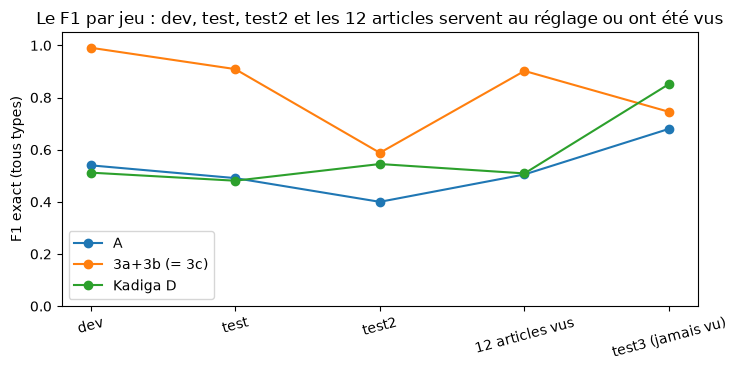

In [24]:
gain_vus = f1("3a+3b", "12 articles") - f1("A :", "12 articles")
gain_test3_arrondi = f1("3a+3b", "corpus_test3") - f1("A :", "corpus_test3")
baisse = f1("3a+3b", "corpus_test3") - f1("3a+3b", "12 articles")

# Les F1 des fichiers sont arrondis à 3 décimales. Pour test3, on a aussi les comptes exacts (VP, prédites, support) :
# F1 = 2 x VP / (prédites + support). On calcule le gain avec ces nombres exacts, pour ne pas ajouter une erreur d'arrondi.
t3 = pd.read_csv(RES / "test3.csv", encoding="utf-8-sig")


def f1_depuis_les_comptes(prefixe_sys):
    r = t3[t3["système"].str.startswith(prefixe_sys) & (t3["type"] == "TOUT (PER+ORG+LOC+DATE)")].iloc[0]
    return 2 * r["VP exact"] / (r["prédites"] + r["support"])


gain_test3 = f1_depuis_les_comptes("3a+3b") - f1_depuis_les_comptes("A :")

print(f"Gain de 3a+3b sur A, sur les 12 articles de réglage : {gain_vus:+.3f}  (environ {gain_vus:+.2f})")
print(f"Gain de 3a+3b sur A, sur test3 (jamais vu)         : {gain_test3:+.4f}  (environ {gain_test3:+.2f})")
print(f"  (avec les F1 déjà arrondis du fichier on trouverait {gain_test3_arrondi:+.3f} : l'écart n'est qu'un effet d'arrondi)")
print(f"Variation du F1 de 3a+3b entre les 12 articles vus et test3 : {baisse:+.3f}")
print(f"A, qui n'est réglé sur rien, passe de {f1('A :', '12 articles'):.3f} à {f1('A :', 'corpus_test3'):.3f} : test3 est plus facile pour tous.")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for nom_s, _ in SYS_CMP:
    ax.plot(range(len(JEUX_CMP)), [tab.loc[nom_s, nj] for nj, _ in JEUX_CMP], marker="o", label=nom_s)
ax.set_xticks(range(len(JEUX_CMP)))
ax.set_xticklabels([nj for nj, _ in JEUX_CMP], rotation=15)
ax.set_ylabel("F1 exact (tous types)")
ax.set_ylim(0, 1.05)
ax.set_title("Le F1 par jeu : dev, test, test2 et les 12 articles servent au réglage ou ont été vus")
ax.legend()
fig.tight_layout()
plt.show()

In [25]:
display(Markdown(f'''**Conclusion de cette section (à dire au jury). Les nombres ci-dessous sont calculés plus haut.**

- Sur les articles de réglage, 3a+3b est **bien meilleur** que spaCy seul : gain de **{gain_vus:+.2f}** de F1 exact.
- Sur `test3`, le gain n'est plus que de **{gain_test3:+.2f}**. Presque tout le gain s'explique donc par le réglage sur nos articles.
- `test3` est plus facile pour tous les systèmes (des pays et des villes connus). C'est pourquoi on compare **au gain sur A**, pas aux scores bruts.
- Sur `test3`, Kadiga D (F1 exact {f1("Kadiga D", "corpus_test3"):.3f}) est **meilleur** que 3a+3b ({f1("3a+3b", "corpus_test3"):.3f}). D n'a pas été réglé sur nos articles.
- Il y a donc des signes **clairs de surapprentissage** de 3a+3b. Avec si peu d'entités, on ne peut pas chiffrer précisément son ampleur.'''))

**Conclusion de cette section (à dire au jury). Les nombres ci-dessous sont calculés plus haut.**

- Sur les articles de réglage, 3a+3b est **bien meilleur** que spaCy seul : gain de **+0.40** de F1 exact.
- Sur `test3`, le gain n'est plus que de **+0.07**. Presque tout le gain s'explique donc par le réglage sur nos articles.
- `test3` est plus facile pour tous les systèmes (des pays et des villes connus). C'est pourquoi on compare **au gain sur A**, pas aux scores bruts.
- Sur `test3`, Kadiga D (F1 exact 0.852) est **meilleur** que 3a+3b (0.745). D n'a pas été réglé sur nos articles.
- Il y a donc des signes **clairs de surapprentissage** de 3a+3b. Avec si peu d'entités, on ne peut pas chiffrer précisément son ampleur.

## 9. Limites et perspectives

### Limites

**Les supports sont petits.** Voici le nombre d'entités réelles par type et par jeu (calculé depuis les fichiers de résultats) :

In [26]:
sup = TOUS[TOUS.système == "A"].pivot(index="type", columns="jeu", values="support")[JEUX].astype(int)
sup.columns = [ETIQUETTE[j] for j in JEUX]
sup.loc[TYPES_AFFICHES]

,dev (optimiste),test (optimiste),test2 (regardé),test3 (jamais vu)
type,,,,
PER,14,7,1,0
ORG,17,13,6,5
LOC,16,4,6,18
DATE,10,3,3,4
TOUT (PER+ORG+LOC+DATE),57,27,16,27
TOUT (PER+ORG+LOC),47,24,13,23


- **Quelques entités seulement par type.** Un seul changement fait bouger le F1 de plusieurs points. On ne peut pas conclure sur de petits écarts.
- **PER à 0 sur `test3`.** On ne peut rien dire des personnes sur ce jeu.
- **Les sujets sont loin de Djibouti.** `test3` parle de la diplomatie indienne, de la défense indienne et de l'économie mondiale. On y mesure la généralisation à d'autres sujets, pas la reconnaissance des entités locales.
- **Il n'y a plus de test neuf.** Les 15 articles du corpus source sont tous utilisés. Toute amélioration future ne pourra plus être mesurée honnêtement ici.
- **Choix de convention.** Une partie des erreurs vient de nos choix d'annotation (événements, mentions courtes, groupements d'États), pas seulement des modèles. Plusieurs lignes de `test3` étaient marquées « à vérifier ».
- **Deux corpus différents.** Les scores sur le corpus de Kadiga et sur La Nation ne se comparent pas.

**Ce que `test3` a montré comme erreurs** (lu depuis `results/test3_ecarts.csv`, système 3a+3b) :

In [27]:
ec = lire_resultat("test3_ecarts.csv")
ec3 = ec[ec["système"].str.startswith("3a+3b")]
print(ec3["écart"].value_counts().to_string(), "\n")
ec3[["id_segment", "écart", "entité", "type", "nature"]].reset_index(drop=True)

résultat lu depuis results/test3_ecarts.csv
écart
EN MOINS (dans le gold, non prédite)    8
EN PLUS (prédite, absente du gold)      5 



,id_segment,écart,entité,type,nature
0,A04_S006,"EN MOINS (dans le gold, non prédite)",BRICS,ORG,totalement manquée
1,A04_S020,"EN PLUS (prédite, absente du gold)",Washington,PER,sans équivalent dans le gold
2,A04_S020,"EN MOINS (dans le gold, non prédite)",Washington,LOC,totalement manquée
3,A04_S025,"EN PLUS (prédite, absente du gold)",Sud,LOC,sans équivalent dans le gold
4,A04_S052,"EN MOINS (dans le gold, non prédite)",BRICS,ORG,totalement manquée
5,A05_S022,"EN MOINS (dans le gold, non prédite)",2016,DATE,totalement manquée
6,A05_S027,"EN MOINS (dans le gold, non prédite)",Innovations for Defence Excellence,ORG,totalement manquée
7,A05_S027,"EN MOINS (dans le gold, non prédite)",mars 2026,DATE,totalement manquée
8,A05_S056,"EN PLUS (prédite, absente du gold)",l'Arménie,LOC,frontière
9,A05_S056,"EN MOINS (dans le gold, non prédite)",Arménie,LOC,frontière


### Perspectives (des idées, pas des résultats)
- **Corriger les erreurs vues sur `test3`** (l'article « l' » dans l'entité, une année seule ou « mars 2026 », « Washington » pris pour une personne),
  puis **annoter de nouveaux articles** pour mesurer honnêtement l'effet.
- **Combiner** les points forts : le modèle ré-entraîné de Kadiga (meilleur sur `test3`) et nos filtres (qui suivent notre guide).
- **Agrandir le corpus annoté** et le diversifier (plus de personnes, plus de textes locaux).
- **Une démonstration interactive** (avec Gradio) pour essayer le système sur un texte libre.

## 10. Visualisation avec displaCy

`displaCy` est l'outil de spaCy qui **colorie les entités dans le texte**. Voici le système 3a+3b sur quatre vrais segments du corpus.
Le texte est le texte réel ; les entités colorées sont ce que **prédit** le système. En dessous : la vérité terrain annotée à la main.

In [28]:
from spacy import displacy

nlp_final = R.construire(groupes=list(R.GROUPES), filtres=list(R.FILTRES_3B_FINAL))
JEU_DE = {s["id"]: (jeu, s["fr"]) for jeu, segs in CORPUS.items() for s in segs}
for id_ in ["A01_S004", "A03_S008", "A12_S001", "A05_S046"]:
    jeu, texte = JEU_DE[id_]
    doc = nlp_final(texte)
    print(f"\n[{id_}] jeu : {jeu}")
    displacy.render(doc, style="ent", jupyter=True)
    vrai = [(a["entite"], a["type"]) for a in ANNOT if a["id_segment"] == id_]
    print("vérité terrain :", vrai)


[A01_S004] jeu : dev


vérité terrain : [('Djibouti', 'LOC'), ('Mariam Hamadou Ali', 'PER'), ('Guelleh Idriss Omar', 'PER')]

[A03_S008] jeu : test


vérité terrain : [("Secrétariat d'État chargé des Sports", 'ORG'), ('Moussa Ali Mohamed', 'PER'), ('Omar Hassan Abdillahi', 'PER')]

[A12_S001] jeu : dev


vérité terrain : [('30 et 31 août 2026', 'DATE'), ('Djibouti-ville', 'LOC')]

[A05_S046] jeu : test3


vérité terrain : [('Philippines', 'LOC'), ('Indonésie', 'LOC'), ('Vietnam', 'LOC')]


**Lire les couleurs.** Chaque couleur est un type (PER, ORG, LOC, DATE). Là où la couleur n'est pas la même que dans la vérité terrain, c'est une erreur.

**La démonstration interactive** (avec Gradio) viendra plus tard dans le dépôt. Aucun lien n'est donné ici tant qu'elle n'existe pas.

---
*Fichiers lus par ce notebook :* `results/` (tous les tableaux), `data/` (les corpus et les annotations), `docs/guide_annotation.md`, `kadiga/` (corpus et résultats de Kadiga),
`src/` (le code : règles, systèmes de Kadiga, score exact et tolérant).